# Training custom models on CIFAR with YOLO and YOLOE

This notebook reuses the first layers (the backbone) of YOLO and of YOLOE, adds new layers, and trains them to classify CIFAR images.

**Plan**
1. The data: CIFAR-10 and CIFAR-100
2. Two backbones: YOLO and YOLOE
3. Three kinds of new layers
4. Training, with validation, early stopping and regularization
5. Experiment: 2 backbones × 3 kinds of layers
6. Results

It follows the ideas of notebook 04.

### Key words

| Word | Meaning | Example |
|---|---|---|
| CIFAR-10 / CIFAR-100 | Two standard sets of 60,000 small colour photos, with 10 or 100 classes | `airplane`, `cat`, `ship` |
| Backbone | The first layers of a model. They turn an image into features | YOLO layers 0 to 10 |
| Head | The last layers. They turn features into the answer | `nn.Linear(256, 10)` |
| Frozen | Layers that do not change during training | The backbone |
| Residual layer | Output = input + a learned correction | `x + self.conv(x)` |
| Self-attention | Every position of the image compares itself with all other positions | The wing "looks at" the tail of the airplane |
| Token | One position of the feature map, seen as a list of numbers | A 4 × 4 map = 16 tokens |
| Validation set | Images kept aside to watch the training | 1,000 images |
| Early stopping | Stop when the validation accuracy no longer improves | Stopped at epoch 12 |
| Weight decay | Regularization: keeps the trained values small | `weight_decay=0.01` |

## 0. Setup
Run this cell once. Expected output: `True`.

Training on a CPU is slow, so only part of the images is used. With a GPU, the numbers can be raised (up to 45,000 / 5,000 / 10,000).

In [5]:
import sys
print("Using this folder's uv environment:", ".venv" in sys.executable)

import copy
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
from ultralytics import YOLO, YOLOE

# Configuration
DATASET = "CIFAR10"  # or "CIFAR100"
TRAIN, VALIDATION, TEST = 10000, 1000, 2000   # number of images used
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Using this folder's uv environment: True
Device: cpu


## 1. The data: CIFAR-10 and CIFAR-100
torchvision downloads both sets from the University of Toronto (about 170 MB each, first time only) into the `data` folder.
Each image is 32 × 32 pixels in colour.

CIFAR10: 50000 training images, 10 classes


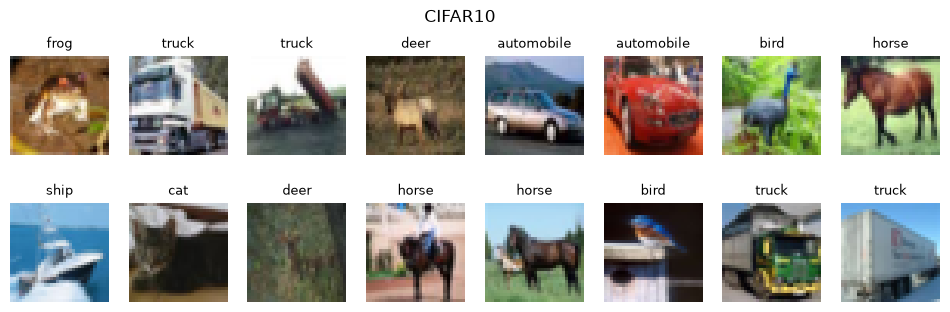

CIFAR100: 50000 training images, 100 classes


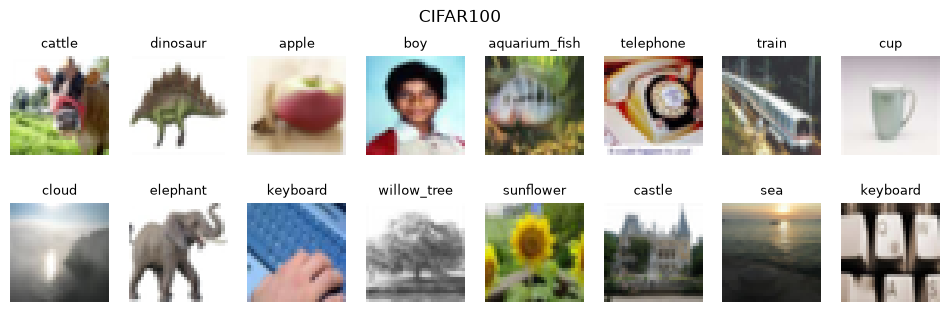

In [6]:
for name in ["CIFAR10", "CIFAR100"]:
    data = getattr(datasets, name)(root="data", train=True, download=True)
    print(f"{name}: {len(data)} training images, {len(data.classes)} classes")

    fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
    for i, ax in enumerate(axes.flat):
        ax.imshow(data.data[i])
        ax.set_title(data.classes[data.targets[i]], fontsize=9)
        ax.axis("off")
    plt.suptitle(name)
    plt.show()

The chosen set (`DATASET`) is split into three groups. The images become tensors of shape `(3, 32, 32)` with values from 0 to 1.

| Group | Used for |
|---|---|
| Training | Learning |
| Validation | Watching the training, to decide when to stop |
| Test | The final score, measured once at the end |

In [8]:
def to_tensors(data, start, count):
    x = torch.tensor(data.data[start:start + count]).permute(0, 3, 1, 2).float() / 255
    y = torch.tensor(data.targets[start:start + count])
    return x, y


train_data = getattr(datasets, DATASET)(root="data", train=True, download=True)
test_data = getattr(datasets, DATASET)(root="data", train=False, download=True)
CLASSES = train_data.classes

x_train, y_train = to_tensors(train_data, 0, TRAIN)
x_val, y_val = to_tensors(train_data, TRAIN, VALIDATION)
x_test, y_test = to_tensors(test_data, 0, TEST)
print(DATASET, "|", len(CLASSES), "classes | training", len(x_train), "| validation", len(x_val), "| test", len(x_test))

CIFAR10 | 10 classes | training 10000 | validation 1000 | test 2000


## 2. Two backbones: YOLO and YOLOE
Both models start with the same 11 layers (0 to 10), but trained differently. The layers are **frozen**.

Only the image layers of YOLOE are reused here. Its word (open-vocabulary) part is not used for classification.

In [10]:
def backbone_layers(name):
    model = YOLO("yolo26n.pt") if name == "YOLO" else YOLOE("yoloe-26n-seg.pt")
    layers = list(model.model.model[:11])  # layers 0 to 10
    for layer in layers:
        layer.requires_grad_(False)        # freeze
    return layers


for name in ["YOLO", "YOLOE"]:
    x = torch.zeros(1, 3, 64, 64)  # one empty 64 x 64 image
    with torch.no_grad():
        for i, layer in enumerate(backbone_layers(name)):
            x = layer(x)
            if i in [6, 10]:
                print(f"{name}: after layer {i:2} -> {tuple(x.shape)}")

YOLO: after layer  6 -> (1, 128, 4, 4)
YOLO: after layer 10 -> (1, 256, 2, 2)
YOLOE: after layer  6 -> (1, 128, 4, 4)
YOLOE: after layer 10 -> (1, 256, 2, 2)


**What to observe:** for both models there are **128** channels after layer 6 and **256** after layer 10.
A new middle layer after layer 6 must therefore use 128 channels, and the head receives 256.

## 3. Three kinds of new layers

| Kind | What is added | Idea |
|---|---|---|
| `head` | Only new last layers | The simplest change |
| `middle` | Head + a residual layer after layer 6 | A small correction inside the backbone |
| `attention` | Head + a self-attention layer after layer 6 | Every position can use information from all other positions |

Both middle layers start as "do nothing" (zeros), so the frozen layers after them are not disturbed at the start.
The first layer of every model doubles the image size (32 → 64 pixels), because YOLO needs larger images.

In [11]:
class ExtraLayer(nn.Module):
    """Residual layer: input + a learned correction."""

    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        nn.init.zeros_(self.conv.weight)
        nn.init.zeros_(self.conv.bias)

    def forward(self, x):
        return x + self.conv(x)


class AttentionLayer(nn.Module):
    """Self-attention: every position looks at all other positions."""

    def __init__(self, channels):
        super().__init__()
        self.attention = nn.MultiheadAttention(channels, num_heads=4, batch_first=True)
        self.strength = nn.Parameter(torch.zeros(1))  # starts at 0 = do nothing

    def forward(self, x):
        b, c, h, w = x.shape
        tokens = x.flatten(2).transpose(1, 2)              # (b, h*w, c): one token per position
        mixed, _ = self.attention(tokens, tokens, tokens)  # every token looks at all tokens
        return x + self.strength * mixed.transpose(1, 2).reshape(b, c, h, w)


# The kinds of models to compare. To try a new middle layer: write its class above, then add one line here.
KINDS = {
    "head": None,                 # no middle layer, only the new head
    "middle": ExtraLayer,         # residual layer after layer 6
    "attention": AttentionLayer,  # self-attention layer after layer 6
}


def build_model(backbone, kind):
    layers = backbone_layers(backbone)
    if KINDS[kind] is not None:
        layers.insert(7, KINDS[kind](128))  # between layers 6 and 7, which has 128 channels
    head = [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, len(CLASSES))]  # new last layers
    return nn.Sequential(nn.Upsample(scale_factor=2), *layers, *head).to(DEVICE)


def trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


for kind in KINDS:
    model = build_model("YOLO", kind)
    output = model(x_train[:2].to(DEVICE))
    print(f"{kind:9} | values to train: {trainable(model):7} | output shape: {tuple(output.shape)}")

head      | values to train:    2570 | output shape: (2, 10)
middle    | values to train:  150154 | output shape: (2, 10)
attention | values to train:   68619 | output shape: (2, 10)


**What to observe:** the output shape is `(2, number of classes)`: one score per class, for each of the 2 test images.

**How to add a new layer**
1. Write a class like `ExtraLayer`. Rule: its output must have the **same shape** as its input (128 channels here).
2. Add one line to `KINDS`. Example: `"my layer": MyLayer,`
3. Run this cell: it prints the output shape, which confirms that the sizes fit. The experiment in section 5 then includes the new kind automatically.

## 4. Training

In [14]:
def accuracy(model, x, y):
    correct = 0
    with torch.no_grad():
        for i in range(0, len(x), 256):  # 256 images at a time
            guesses = model(x[i:i + 256].to(DEVICE)).argmax(1).cpu()
            correct += (guesses == y[i:i + 256]).sum().item()
    return correct / len(x)


def train(model, max_epochs=30, patience=5, weight_decay=0.01):
    model.eval()  # keeps the frozen layers unchanged; the new layers still learn
    values = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(values, lr=0.001, weight_decay=weight_decay)
    best_accuracy, best_values, waited = 0, None, 0

    for epoch in range(max_epochs):
        order = torch.randperm(len(x_train))  # a new order in every epoch
        for i in range(0, len(x_train), 64):  # batches of 64 images
            batch = order[i:i + 64]
            loss = F.cross_entropy(model(x_train[batch].to(DEVICE)), y_train[batch].to(DEVICE))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_accuracy = accuracy(model, x_train, y_train)
        validation_accuracy = accuracy(model, x_val, y_val)
        print(f"epoch {epoch + 1}: loss {loss.item():.3f} | train {train_accuracy:.1%} | validation {validation_accuracy:.1%}")

        if validation_accuracy > best_accuracy:  # better: remember this version
            best_accuracy, best_values, waited = validation_accuracy, copy.deepcopy(model.state_dict()), 0
        else:
            waited += 1
            if waited == patience:
                print(f"Stopped early at epoch {epoch + 1}.")
                break
    model.load_state_dict(best_values)  # go back to the best version

## 5. Experiment: 2 backbones × 3 kinds of layers
Six models are trained, one after another. On a CPU this takes several minutes.

In [15]:
results = {}
for backbone in ["YOLO", "YOLOE"]:
    for kind in KINDS:
        print(f"\n=== {backbone} + {kind} ===")
        torch.manual_seed(0)
        model = build_model(backbone, kind)
        train(model)
        results[f"{backbone} + {kind}"] = {
            "values trained": trainable(model),
            "train": round(100 * accuracy(model, x_train, y_train), 1),
            "validation": round(100 * accuracy(model, x_val, y_val), 1),
            "test": round(100 * accuracy(model, x_test, y_test), 1),
        }


=== YOLO + head ===
epoch 1: loss 1.852 | train 53.2% | validation 52.0%
epoch 2: loss 1.140 | train 55.8% | validation 56.1%
epoch 3: loss 1.132 | train 57.9% | validation 56.9%
epoch 4: loss 1.532 | train 60.1% | validation 58.7%
epoch 5: loss 1.308 | train 61.3% | validation 59.8%
epoch 6: loss 1.000 | train 61.8% | validation 60.3%
epoch 7: loss 1.199 | train 62.7% | validation 59.9%
epoch 8: loss 1.020 | train 63.3% | validation 61.0%
epoch 9: loss 0.992 | train 63.7% | validation 61.1%
epoch 10: loss 0.966 | train 64.2% | validation 62.3%
epoch 11: loss 0.841 | train 64.5% | validation 63.0%
epoch 12: loss 1.467 | train 65.3% | validation 62.3%
epoch 13: loss 1.513 | train 65.4% | validation 63.0%
epoch 14: loss 0.816 | train 65.8% | validation 63.3%
epoch 15: loss 0.773 | train 65.9% | validation 64.0%
epoch 16: loss 1.122 | train 66.3% | validation 63.9%
epoch 17: loss 1.103 | train 66.3% | validation 63.7%
epoch 18: loss 1.076 | train 66.8% | validation 63.3%
epoch 19: loss 0

## 6. Results
Accuracy in percent.

In [16]:
table = pd.DataFrame(results).T
table

,values trained,train,validation,test
YOLO + head,2570.0,67.8,64.8,62.9
YOLO + middle,150154.0,96.4,77.8,78.1
YOLO + attention,68619.0,90.7,76.2,77.6
YOLOE + head,2570.0,66.8,64.2,64.3
YOLOE + middle,150154.0,97.1,76.8,77.0
YOLOE + attention,68619.0,86.5,75.7,76.4


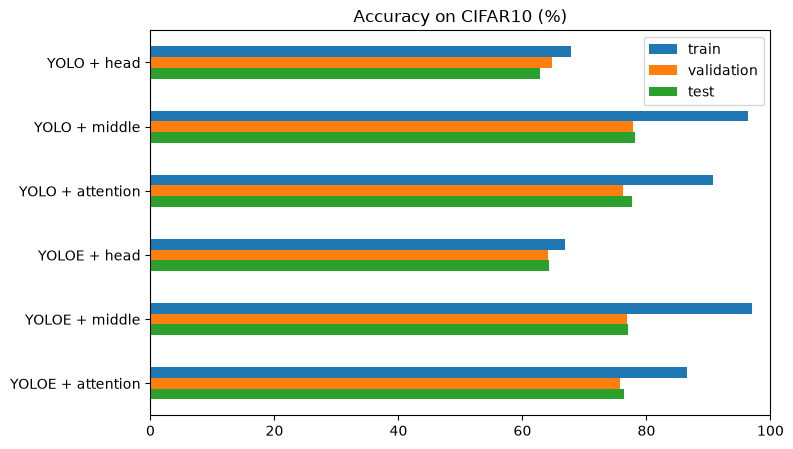

In [17]:
table[["train", "validation", "test"]].plot.barh(figsize=(8, 5), xlim=(0, 100), title=f"Accuracy on {DATASET} (%)")
plt.gca().invert_yaxis()
plt.show()